# Data Visualization with Matplotlib & Seaborn
**Student Project - InternCircle Task 2**

### Overview
In this project, I used the **Tips dataset** to create clean, honest, and easy-to-read charts using Matplotlib and Seaborn.

I selected four specific questions:
1. **How are bills distributed?** (Histogram)
2. **Do tips differ by day?** (Box plot)
3. **Does a bigger bill mean a bigger tip?** (Scatter plot)
4. **Which numbers move together?** (Correlation heatmap)
5. **Bonus Question: Which day has the highest average bill?** (Bar chart with honest zero baseline)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style and color palette
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['font.sans-serif'] = 'Arial'

# Load tips dataset
tips = pd.read_csv("tips.csv")
print("Dataset loaded successfully!")
tips.head()

Dataset loaded successfully!
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [2]:
# Check summary statistics
tips.describe().round(2)

       total_bill     tip    size
count      244.00  244.00  244.00
mean        19.79    3.00    2.57
std          8.90    1.38    0.95
min          3.07    1.00    1.00
25%         13.35    2.00    2.00
50%         17.80    2.90    2.00
75%         24.13    3.56    3.00
max         50.81   10.00    6.00


---
### 1. How are total bills distributed?
I used a histogram with KDE to show the distribution of continuous total bills.


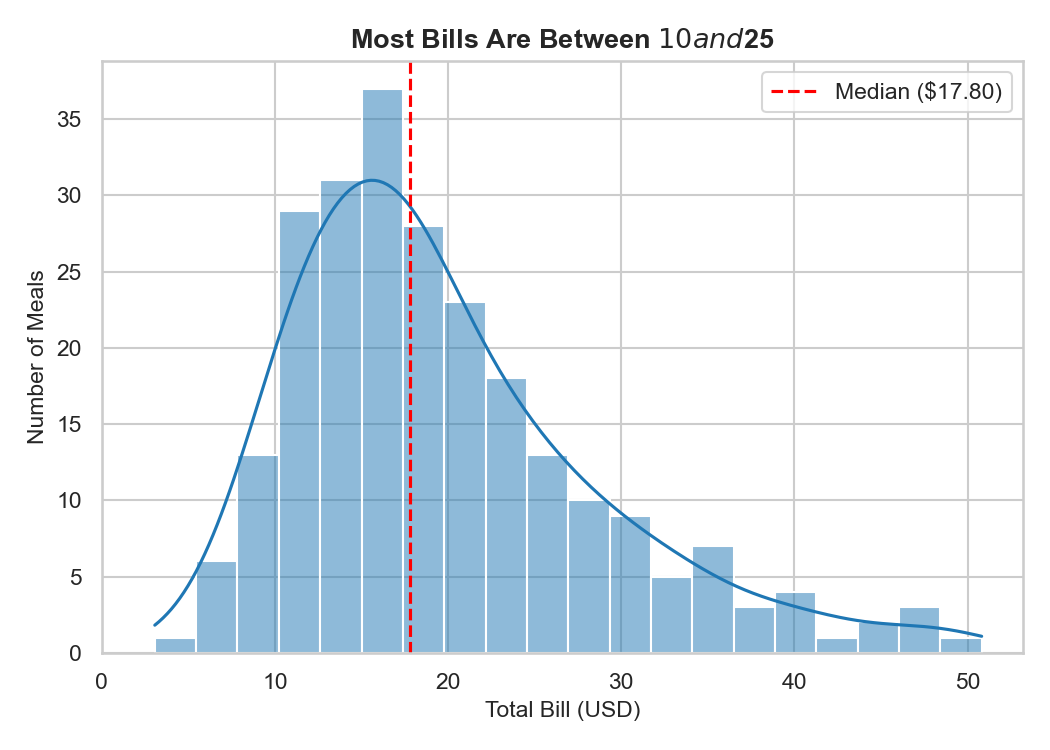

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(tips["total_bill"], bins=20, kde=True, ax=ax, color="#1f77b4")

median_bill = tips["total_bill"].median()
ax.axvline(median_bill, color="red", linestyle="--", label=f"Median (${median_bill:.2f})")

ax.set_title("Most Bills Are Between $10 and $25", fontsize=13, fontweight="bold")
ax.set_xlabel("Total Bill (USD)")
ax.set_ylabel("Number of Meals")
ax.set_xlim(left=0)
ax.legend()

plt.tight_layout()
plt.show()

**Takeaway:** Most customer bills fall between \$10 and \$25 (median is \$17.80). The distribution is skewed to the right because bills over \$40 are relatively uncommon.

---
### 2. Do tips differ by day?
I used a box plot to compare the spread and median tips across Thursday, Friday, Saturday, and Sunday.


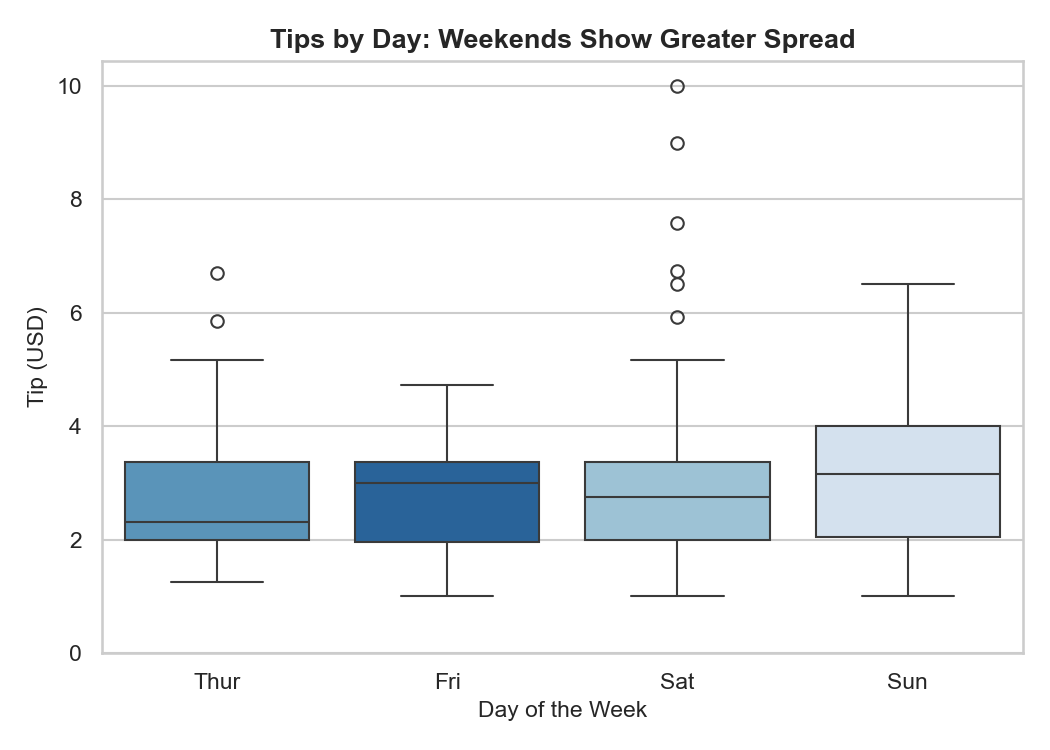

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
day_order = ["Thur", "Fri", "Sat", "Sun"]

sns.boxplot(data=tips, x="day", y="tip", hue="day", legend=False, order=day_order, palette="Blues", ax=ax)
ax.set_title("Tips by Day: Weekends Show Greater Spread", fontsize=13, fontweight="bold")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Tip (USD)")
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

**Takeaway:** While the median tip stays around \$2.75 to \$3.00 every day, Saturday and Sunday have a wider spread and the highest tips (outliers up to \$10).

---
### 3. Does a bigger bill mean a bigger tip?
I used a scatter plot with hue for meal time (Lunch vs. Dinner) and an overlaid trendline.


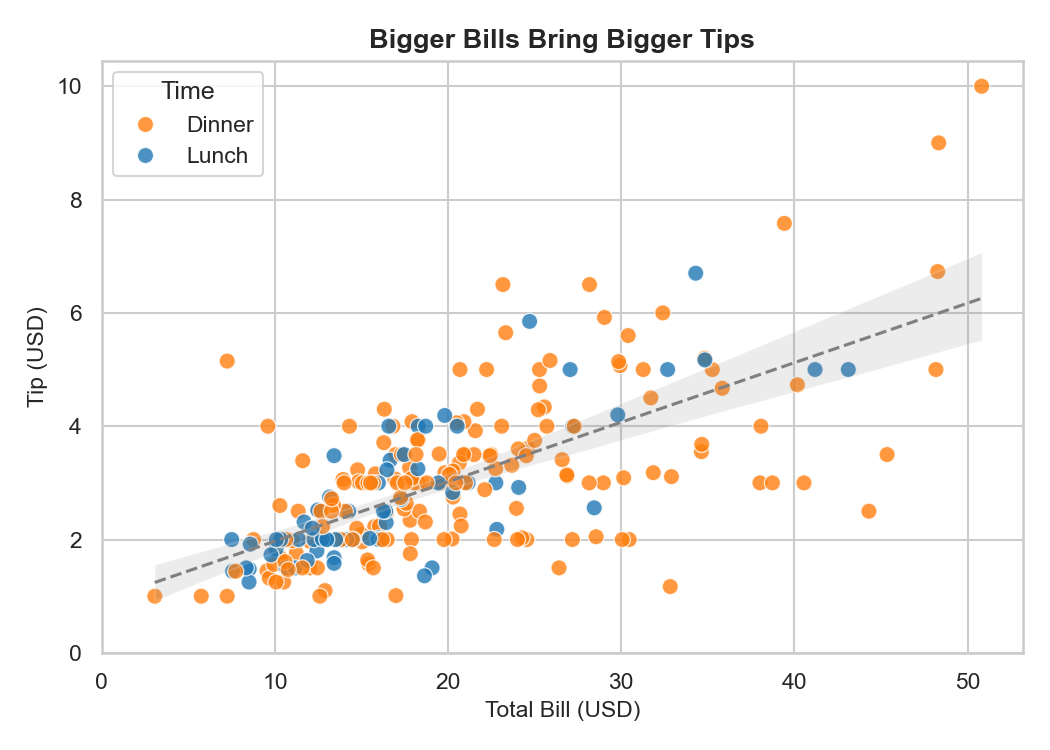

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette={"Lunch": "#1f77b4", "Dinner": "#ff7f0e"},
    alpha=0.8,
    s=60,
    ax=ax
)
sns.regplot(
    data=tips,
    x="total_bill",
    y="tip",
    scatter=False,
    color="gray",
    line_kws={"linestyle": "--", "linewidth": 1.5},
    ax=ax
)

ax.set_title("Bigger Bills Bring Bigger Tips", fontsize=13, fontweight="bold")
ax.set_xlabel("Total Bill (USD)")
ax.set_ylabel("Tip (USD)")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend(title="Time")

plt.tight_layout()
plt.show()

**Takeaway:** There is a clear positive trend showing that higher bills result in higher tips across both lunch and dinner.

---
### 4. Which numbers move together?
I computed the correlation matrix of numerical columns and plotted it as an annotated heatmap.


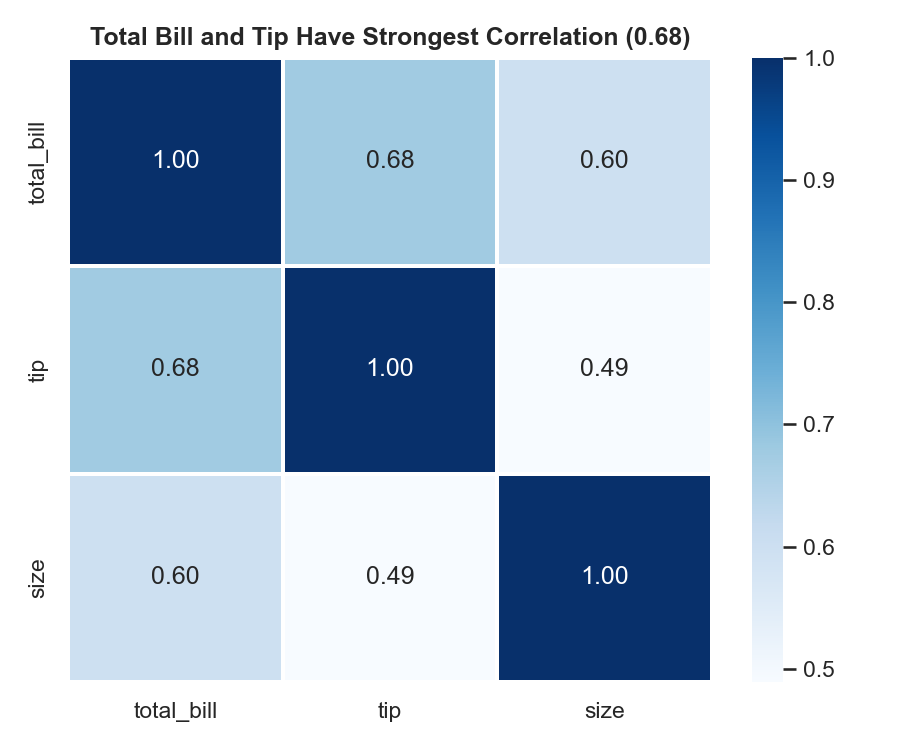

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
corr = tips.select_dtypes("number").corr()

sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f", linewidths=1, ax=ax)
ax.set_title("Total Bill and Tip Have Strongest Correlation (0.68)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

**Takeaway:** Total bill and tip have the strongest relationship (r = 0.68), followed by party size and bill (r = 0.60).

---
### 5. Bonus: Average Total Bill by Day
A bar chart with an honest zero baseline ($y=0$) to compare average bills by day.


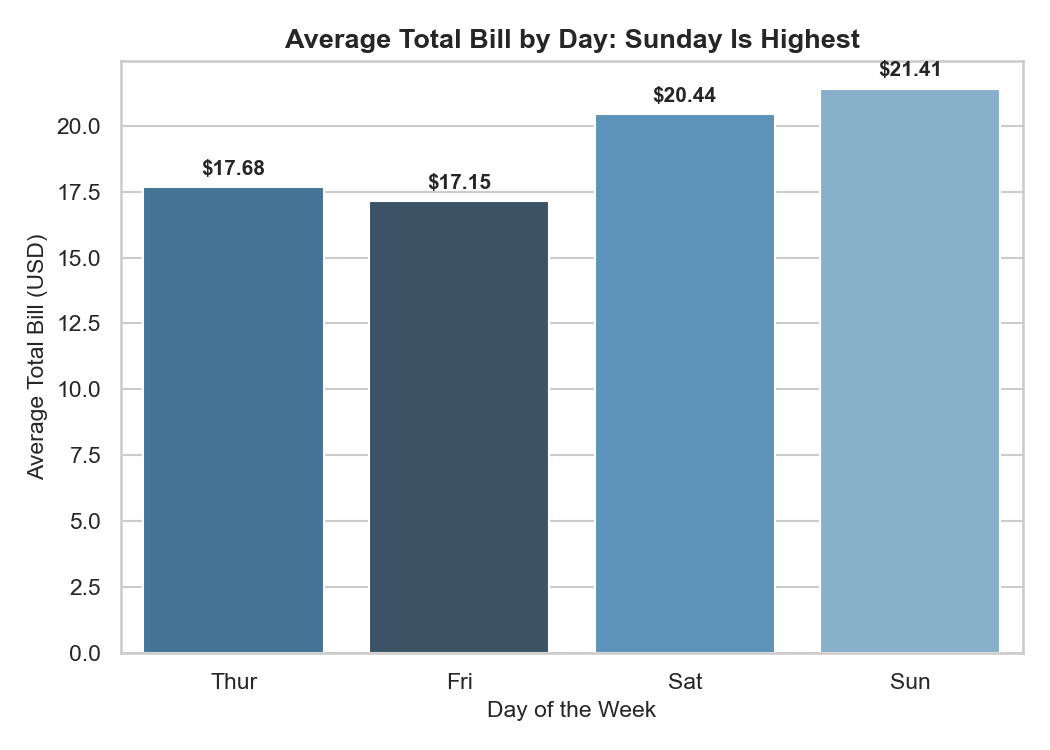

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(data=tips, x="day", y="total_bill", hue="day", legend=False, order=day_order, palette="Blues_d", errorbar=None, ax=ax)
ax.set_title("Average Total Bill by Day: Sunday Is Highest", fontsize=13, fontweight="bold")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Total Bill (USD)")
ax.set_ylim(bottom=0)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"${height:.2f}",
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

**Takeaway:** Sunday has the highest average meal spend (\$21.41), followed by Saturday (\$20.44), while Thursday (\$17.68) and Friday (\$17.15) are lower.

---
### 6. Four charts in one figure (2x2 Dashboard)
Combining the four core charts into a single figure and saving at 150 DPI as required.


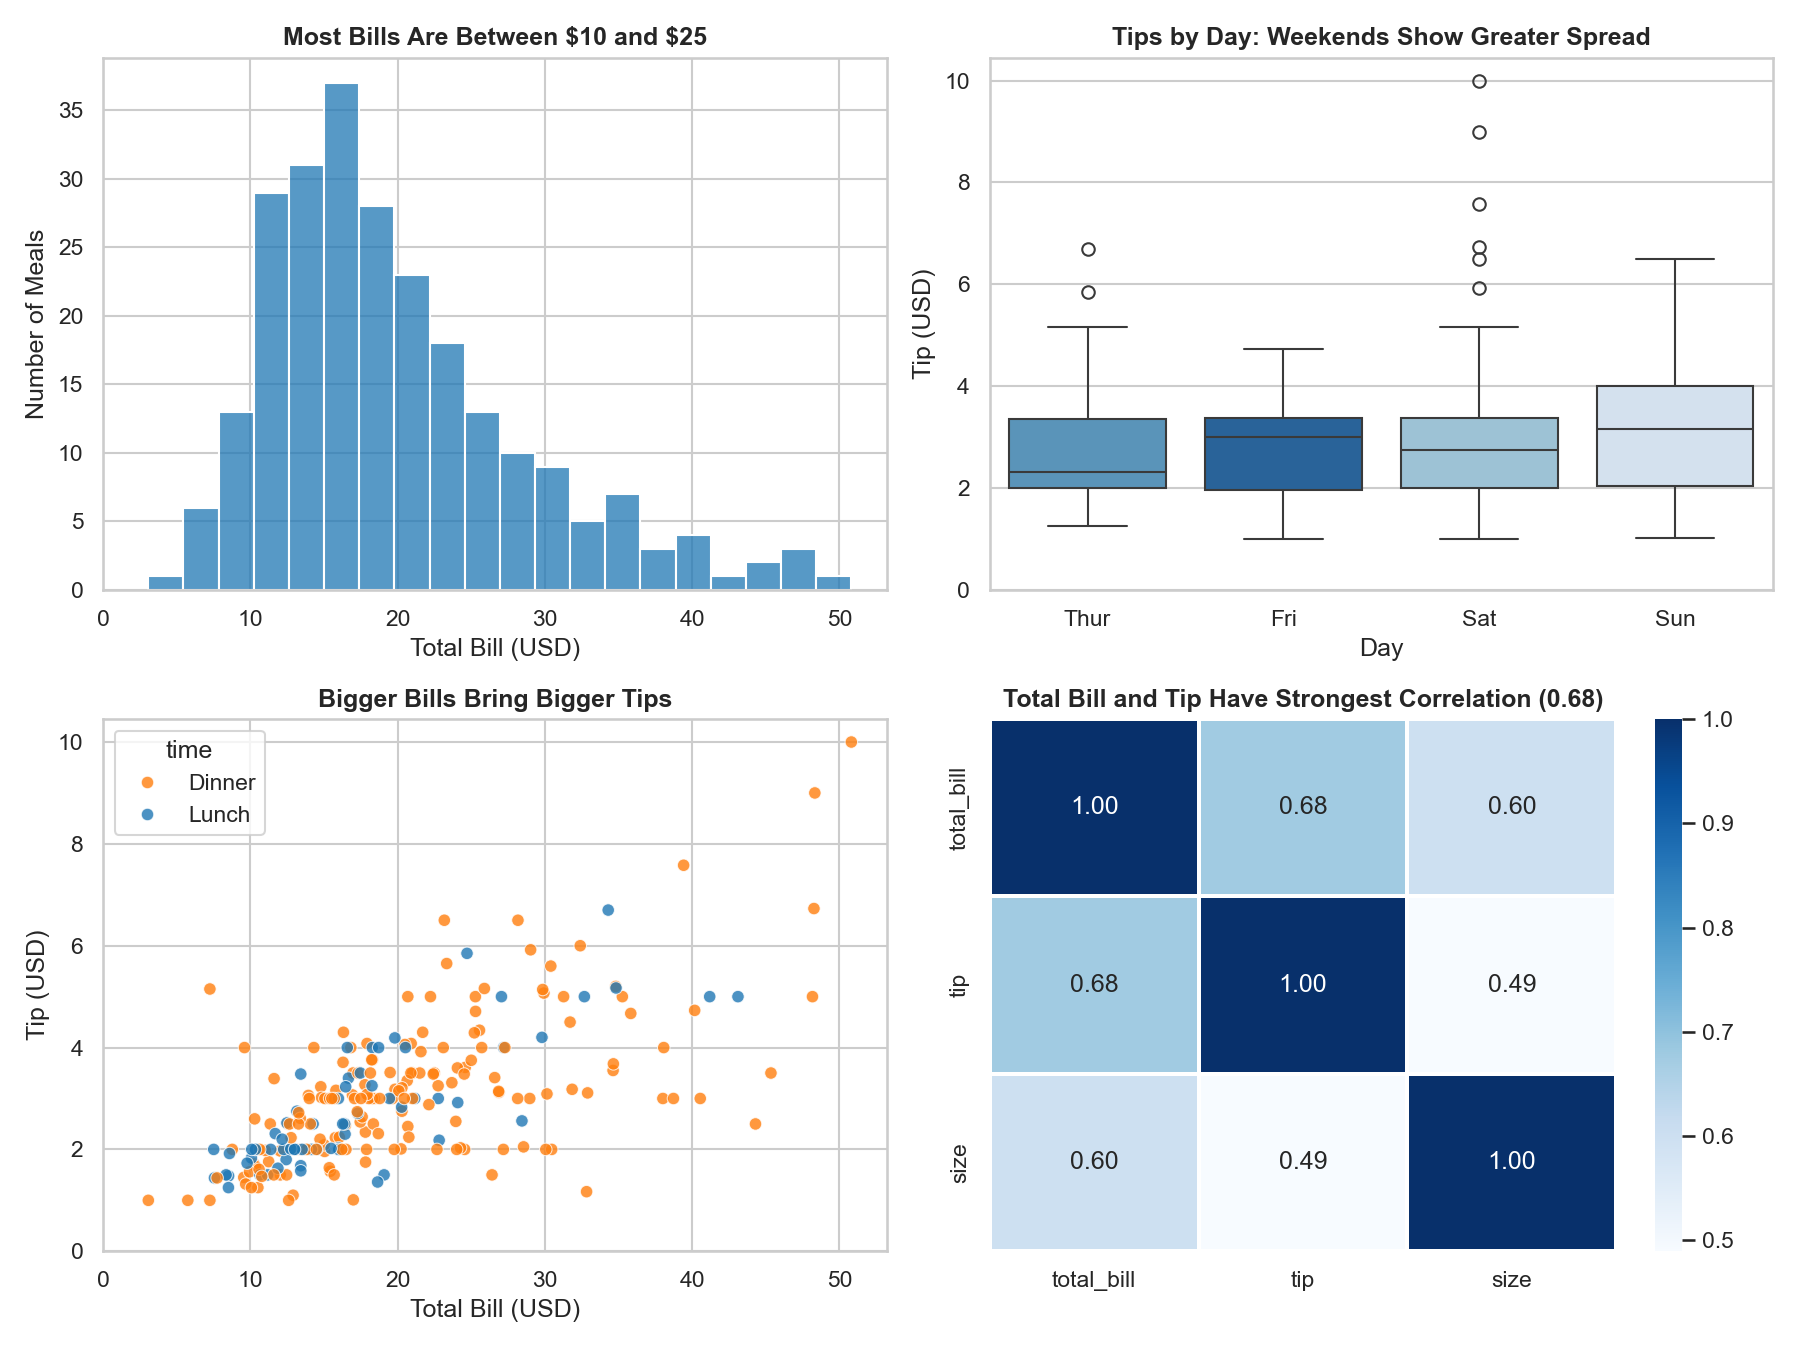

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Chart 1: Histplot
sns.histplot(tips["total_bill"], bins=20, ax=axes[0, 0], color="#1f77b4")
axes[0, 0].set_title(r"Most Bills Are Between \$10 and \$25", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Total Bill (USD)")
axes[0, 0].set_ylabel("Number of Meals")
axes[0, 0].set_xlim(left=0)

# Chart 2: Boxplot
sns.boxplot(data=tips, x="day", y="tip", hue="day", legend=False, order=day_order, palette="Blues", ax=axes[0, 1])
axes[0, 1].set_title("Tips by Day: Weekends Show Greater Spread", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Tip (USD)")
axes[0, 1].set_ylim(bottom=0)

# Chart 3: Scatterplot
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette={"Lunch": "#1f77b4", "Dinner": "#ff7f0e"},
    alpha=0.8,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Bigger Bills Bring Bigger Tips", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Total Bill (USD)")
axes[1, 0].set_ylabel("Tip (USD)")
axes[1, 0].set_xlim(left=0)
axes[1, 0].set_ylim(bottom=0)

# Chart 4: Heatmap
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f", linewidths=1, ax=axes[1, 1])
axes[1, 1].set_title("Total Bill and Tip Have Strongest Correlation (0.68)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("tips_overview.png", dpi=150)
plt.show()

---
### Review Checklist
- [x] Each chart type matches its question
- [x] Titles state the findings directly (e.g. "Bigger Bills Bring Bigger Tips")
- [x] Bar chart y-axis starts at zero
- [x] Colorblind-friendly palette used (Blue/Orange, no red-green clashes)
- [x] `plt.tight_layout()` used to avoid clipped labels
- [x] One-line takeaway under every chart
- [x] Saved 2x2 dashboard at 150 DPI (`tips_overview.png`)
